# Mini Project 1: Text Analysis
**Casey Collins (ccolli78)** — CS 445, Fall 2026

## Goal
Use word frequencies as a fingerprint of an author's style. I want to answer three questions:

1. Do two works by the **same author** have similar word-frequency profiles?
2. Do works by **two different authors** differ more than two works by the same author?
3. Which specific words does one author **prefer** that the other uses much less?

Extra credit: does the count of a common word such as *would* follow a binomial distribution
across chunks of a book, as it should if each word were an independent trial?

## Data sources
Plain-text novels from [Project Gutenberg](https://www.gutenberg.org), stored in `data/`:

| Author | Work | Gutenberg ID |
|---|---|---|
| Jane Austen | Pride and Prejudice | 1342 |
| Jane Austen | Emma | 158 |
| Charles Dickens | A Tale of Two Cities | 98 |
| Charles Dickens | Great Expectations | 1400 |

I picked two authors from the same century and country so that differences reflect style rather than era or dialect.

## Approach
1. Strip Gutenberg headers and footers, lowercase, tokenize on non-letters, drop stop words.
2. Build a relative word-frequency table (counts per 10,000 words) for each work.
3. Compare works with (a) rank correlation of shared-word frequencies, (b) Jaccard overlap of top-N vocabularies, and (c) scatter plots of frequencies.
4. Find preferred words with a log-ratio of smoothed frequencies between authors, and check them with a chi-square test.
5. Extra credit: split a book into fixed-size chunks, count *would* in each, and compare to a binomial fit.


## 1. Load and clean the texts
Each Gutenberg file has a licence header and footer marked by `*** START ...` and `*** END ...` lines. I keep only the body, then tokenize.

In [1]:
import re, os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

WORKS = {
    'Austen: Pride and Prejudice': ('Austen',  'data/pg1342.txt'),
    'Austen: Emma':                ('Austen',  'data/pg158.txt'),
    'Dickens: A Tale of Two Cities': ('Dickens', 'data/pg98.txt'),
    'Dickens: Great Expectations':   ('Dickens', 'data/pg1400.txt'),
}

def load_gutenberg(path):
    # errors='replace' avoids unicode crashes on odd bytes (as noted in the class notebook)
    with open(path, encoding='utf-8', errors='replace') as f:
        raw = f.read()
    start = re.search(r'\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', raw)
    end   = re.search(r'\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK', raw)
    body = raw[start.end():end.start()] if start and end else raw
    return body

texts = {name: load_gutenberg(p) for name, (_, p) in WORKS.items()}
for name, t in texts.items():
    print(f'{name:32s} {len(t):>10,} characters')

Austen: Pride and Prejudice         728,751 characters
Austen: Emma                        880,434 characters
Dickens: A Tale of Two Cities       757,611 characters
Dickens: Great Expectations         994,623 characters


### Tokenizing
I lowercase everything and split on anything that is not a letter or apostrophe, so `don't` stays one token but `well-known` becomes two. Stop words (the, of, and ...) are removed for the vocabulary comparisons because they dominate every English text and hide stylistic differences. I keep a separate *unfiltered* token list for the extra-credit question, where function words like *would* are exactly what we want.

In [2]:
STOP = set(stopwords.words('english'))

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

tokens_all = {name: tokenize(t) for name, t in texts.items()}          # everything
tokens     = {name: [w for w in toks if w not in STOP and len(w) > 1]  # content words only
              for name, toks in tokens_all.items()}

summary = pd.DataFrame({
    'author':        [WORKS[n][0] for n in WORKS],
    'total_tokens':  [len(tokens_all[n]) for n in WORKS],
    'content_tokens':[len(tokens[n]) for n in WORKS],
    'vocab_size':    [len(set(tokens[n])) for n in WORKS],
}, index=list(WORKS))
summary['type_token_ratio'] = (summary.vocab_size / summary.content_tokens).round(3)
summary

,author,total_tokens,content_tokens,vocab_size,type_token_ratio
Austen: Pride and Prejudice,Austen,128565,58063,6584,0.113
Austen: Emma,Austen,162099,73368,6954,0.095
Dickens: A Tale of Two Cities,Dickens,138490,64366,9544,0.148
Dickens: Great Expectations,Dickens,189051,83094,10594,0.127


### Relative frequencies
The books have different lengths, so raw counts are not comparable. I convert every count to **occurrences per 10,000 content words**.

In [3]:
counts = {name: Counter(toks) for name, toks in tokens.items()}
freq = pd.DataFrame(counts).fillna(0)
per10k = freq / freq.sum() * 10_000
per10k.round(2).sort_values(list(WORKS)[0], ascending=False).head(15)

,Austen: Pride and Prejudice,Austen: Emma,Dickens: A Tale of Two Cities,Dickens: Great Expectations
mr,139.16,157.29,96.63,85.57
elizabeth,111.09,1.09,0.00,0.00
could,91.45,114.08,43.81,58.13
would,83.53,111.90,53.29,72.09
darcy,74.40,0.00,0.00,0.00
said,69.92,65.97,102.69,162.35
mrs,60.97,95.55,2.80,19.74
bennet,58.38,0.00,0.00,0.00
much,58.04,66.24,28.74,37.43
miss,54.25,82.05,36.20,46.09


## 2. Obstacle: character names
The top of every list is full of names (*elizabeth*, *darcy*, *bennet*). Those tell us which book we are reading, not how the author writes. I flag a word as a **proper noun** if it is capitalized in at least 90% of its occurrences in the original text, and drop those from the style comparison. Sentence-initial words are sometimes capitalized, but no ordinary word reaches 90%.

In [4]:
def proper_nouns(text, min_count=5, threshold=0.9):
    raw = re.findall(r"[A-Za-z]+(?:'[a-z]+)?", text)
    total, caps = Counter(w.lower() for w in raw), Counter(w.lower() for w in raw if w[0].isupper())
    return {w for w, n in total.items() if n >= min_count and caps[w] / n >= threshold}

names = set().union(*(proper_nouns(t) for t in texts.values()))
print(len(names), 'proper-noun types removed, e.g.:', sorted(names)[:12])

ctoks  = {n: [w for w in toks if w not in names] for n, toks in tokens.items()}   # content words, no names
freq   = pd.DataFrame({n: Counter(t) for n, t in ctoks.items()}).fillna(0)
per10k = freq / freq.sum() * 10_000
per10k.round(1).sort_values('Austen: Emma', ascending=False).head(12)

314 proper-noun types removed, e.g.: ['abbaye', 'abbey', 'abel', 'addison', 'aged', 'ah', 'alexandre', 'allen', 'anne', 'antoine', 'arthur', 'attorney']


,Austen: Pride and Prejudice,Austen: Emma,Dickens: A Tale of Two Cities,Dickens: Great Expectations
could,102.9,129.9,47.3,62.9
would,94.0,127.4,57.6,78.0
must,61.1,88.6,17.0,25.8
much,65.3,75.4,31.1,40.5
said,78.7,75.1,111.0,175.7
one,57.2,71.1,74.0,66.7
every,35.9,67.5,20.5,12.5
well,44.6,62.5,30.0,39.6
thing,5.8,61.9,8.2,12.1
think,43.0,59.6,20.6,31.4


## 3. Same author vs. different authors
Three ways to measure how similar two works are:

* **Spearman rank correlation** of per-10k frequencies over words that appear in both works (order-based, robust to a few huge outliers).
* **Jaccard overlap** of the top-200 vocabularies: |A ∩ B| / |A ∪ B|.
* **Scatter plots** of log frequencies, where a tight diagonal means similar usage.

In [5]:
from scipy.stats import spearmanr
from itertools import combinations

def top_set(col, n=200):
    return set(per10k[col].sort_values(ascending=False).head(n).index)

rows = []
for a, b in combinations(per10k.columns, 2):
    both = per10k[(per10k[a] > 0) & (per10k[b] > 0)]
    rho, _ = spearmanr(both[a], both[b])
    ta, tb = top_set(a), top_set(b)
    rows.append({'work A': a, 'work B': b,
                 'pair': 'same author' if WORKS[a][0] == WORKS[b][0] else 'different authors',
                 'shared words': len(both),
                 'spearman rho': round(rho, 3),
                 'jaccard top200': round(len(ta & tb) / len(ta | tb), 3)})
pairs = pd.DataFrame(rows).sort_values('spearman rho', ascending=False)
pairs

,work A,work B,pair,shared words,spearman rho,jaccard top200
0,Austen: Pride and Prejudice,Austen: Emma,same author,4222,0.750,0.674
5,Dickens: A Tale of Two Cities,Dickens: Great Expectations,same author,5854,0.657,0.613
2,Austen: Pride and Prejudice,Dickens: Great Expectations,different authors,4202,0.582,0.460
4,Austen: Emma,Dickens: Great Expectations,different authors,4423,0.568,0.471
1,Austen: Pride and Prejudice,Dickens: A Tale of Two Cities,different authors,3924,0.535,0.384
3,Austen: Emma,Dickens: A Tale of Two Cities,different authors,4178,0.524,0.399


In [6]:
pairs.groupby('pair')[['spearman rho', 'jaccard top200']].mean().round(3)

,spearman rho,jaccard top200
pair,,
different authors,0.552,0.428
same author,0.704,0.644


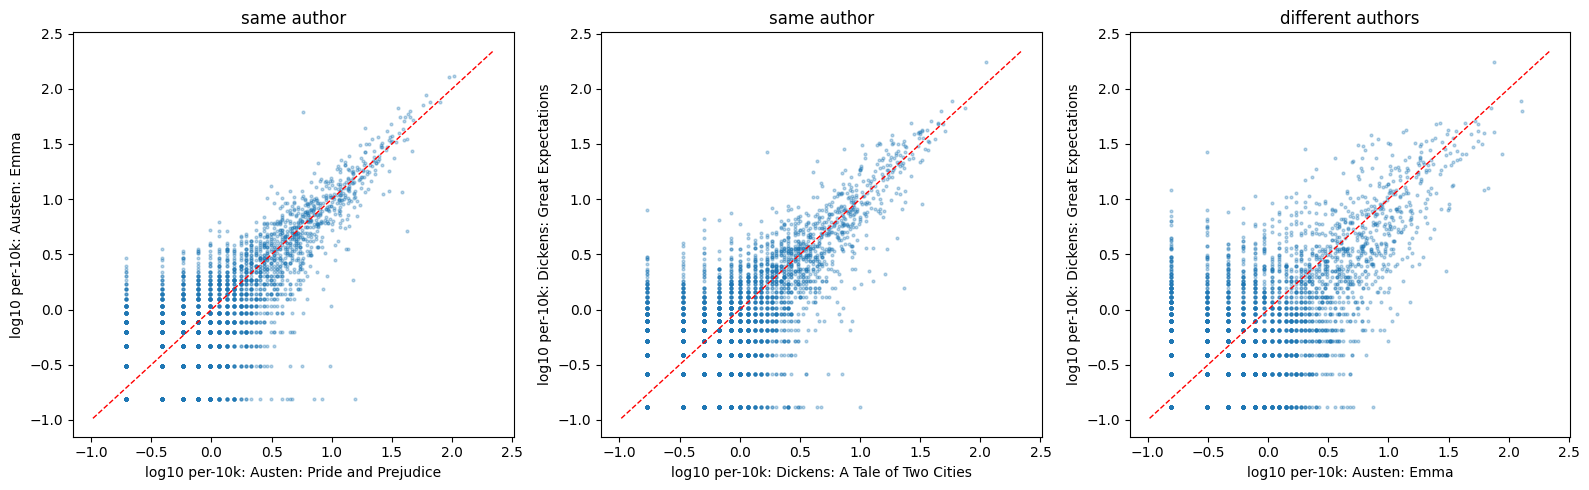

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
show = [('Austen: Pride and Prejudice', 'Austen: Emma'),
        ('Dickens: A Tale of Two Cities', 'Dickens: Great Expectations'),
        ('Austen: Emma', 'Dickens: Great Expectations')]
for ax, (a, b) in zip(axes, show):
    both = per10k[(per10k[a] > 0) & (per10k[b] > 0)]
    ax.scatter(np.log10(both[a]), np.log10(both[b]), s=4, alpha=0.3)
    lim = [np.log10(per10k.values[per10k.values > 0].min()) - 0.1, np.log10(per10k.values.max()) + 0.1]
    ax.plot(lim, lim, 'r--', lw=1)
    ax.set_xlabel(f'log10 per-10k: {a}'); ax.set_ylabel(f'log10 per-10k: {b}')
    ax.set_title('same author' if WORKS[a][0] == WORKS[b][0] else 'different authors')
plt.tight_layout(); plt.show()

## 4. Words one author prefers
I pool each author's two books, add a small pseudo-count (Laplace smoothing) so words that are absent from one author do not give infinite ratios, and compute
`log2( freq_Austen / freq_Dickens )`. A value of +3 means Austen uses the word about 8× more often per word written.
To make sure a difference is not a fluke of one book, I only keep words that appear in **both** of the preferring author's books, and I check the top hits with a chi-square test on the raw counts.

In [8]:
from scipy.stats import chi2_contingency

by_author = {}
for auth in ['Austen', 'Dickens']:
    cols = [n for n in WORKS if WORKS[n][0] == auth]
    by_author[auth] = freq[cols].sum(axis=1)
A, D = by_author['Austen'], by_author['Dickens']
NA, ND = A.sum(), D.sum()
alpha = 0.5
lr = np.log2(((A + alpha) / (NA + alpha * len(A))) / ((D + alpha) / (ND + alpha * len(D))))

in_both_austen  = (freq[[n for n in WORKS if WORKS[n][0]=='Austen']]  > 0).all(axis=1)
in_both_dickens = (freq[[n for n in WORKS if WORKS[n][0]=='Dickens']] > 0).all(axis=1)
minc = 20   # require a reasonable amount of evidence

def pvalue(w):
    table = [[A[w], NA - A[w]], [D[w], ND - D[w]]]
    return chi2_contingency(table)[1]

austen_pref  = lr[in_both_austen  & (A >= minc)].sort_values(ascending=False).head(20)
dickens_pref = lr[in_both_dickens & (D >= minc)].sort_values().head(20)

def table(sel):
    return pd.DataFrame({'Austen count': A[sel.index].astype(int), 'Dickens count': D[sel.index].astype(int),
                         'log2 ratio (A/D)': sel.round(2),
                         'chi2 p-value': [f'{pvalue(w):.1e}' for w in sel.index]})
print('Words Austen prefers'); display(table(austen_pref))
print('Words Dickens prefers'); display(table(dickens_pref))

Words Austen prefers


,Austen count,Dickens count,log2 ratio (A/D),chi2 p-value
civility,54,0,6.99,4.9e-15
pleasing,47,0,6.79,3.2e-13
pianoforte,27,0,6.00,5.3e-08
regiment,25,0,5.89,1.8e-07
library,24,0,5.83,3.3e-07
excessively,22,0,5.71,1.1e-06
probability,22,0,5.71,1.1e-06
inferior,22,0,5.71,1.1e-06
prevailed,21,0,5.64,2.0e-06
attentions,56,1,5.45,6.9e-15


Words Dickens prefers


,Austen count,Dickens count,log2 ratio (A/D),chi2 p-value
prison,0,104,-7.49,1.3e-20
spy,0,61,-6.72,1.5e-12
boat,0,54,-6.55,3.1e-11
forge,0,54,-6.55,3.1e-11
straight,0,52,-6.50,7.3e-11
boots,0,51,-6.47,1.1e-10
pipe,0,50,-6.44,1.8e-10
prisoner,1,150,-6.43,1.3e-28
courtyard,0,47,-6.35,6.5e-10
fountain,0,47,-6.35,6.5e-10


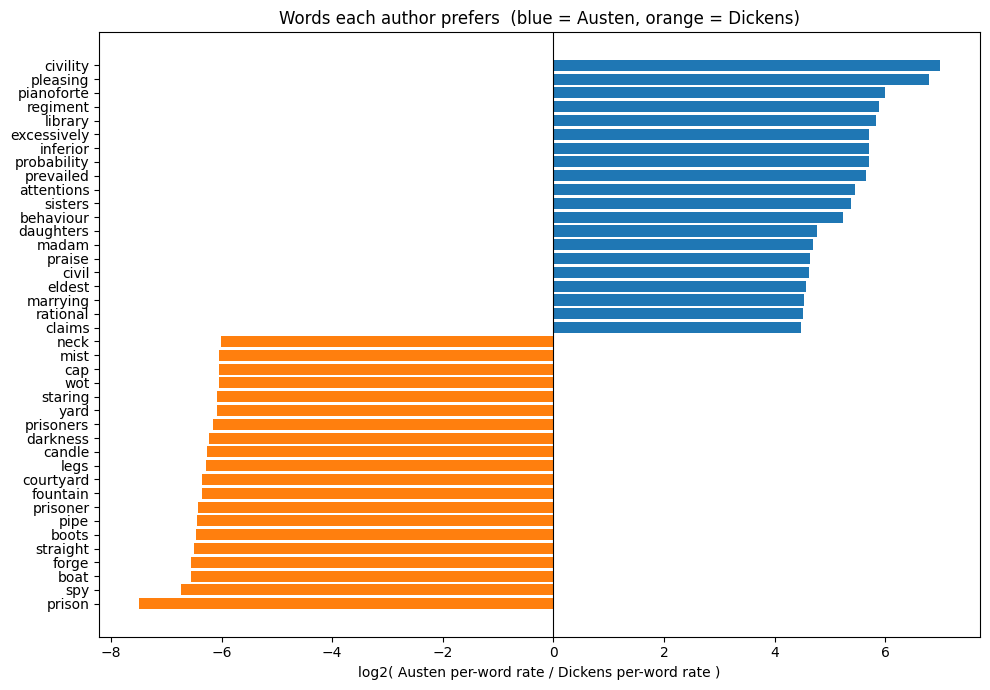

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
both = pd.concat([austen_pref, dickens_pref]).sort_values()
ax.barh(both.index, both.values, color=['tab:orange' if v < 0 else 'tab:blue' for v in both.values])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('log2( Austen per-word rate / Dickens per-word rate )')
ax.set_title('Words each author prefers  (blue = Austen, orange = Dickens)')
plt.tight_layout(); plt.show()

### The shared backbone
A sanity check in the other direction: the most common content words overall, and how evenly the two authors use them. Words with a ratio near 0 are the common core of 19th-century English narrative.

In [10]:
common = (A + D).sort_values(ascending=False).head(25).index
pd.DataFrame({'Austen per10k': (A[common]/NA*1e4).round(1), 'Dickens per10k': (D[common]/ND*1e4).round(1),
              'log2 ratio': lr[common].round(2)})

,Austen per10k,Dickens per10k,log2 ratio
said,76.7,147.4,-0.96
would,112.5,69.1,0.69
could,117.9,56.1,1.06
one,64.9,69.9,-0.12
much,70.9,36.4,0.95
know,50.1,45.6,0.12
little,47.7,46.8,0.01
must,76.4,21.9,1.78
time,41.5,47.0,-0.20
well,54.5,35.4,0.61
